# Självstudieövningar – Vecka 6

De här övningarna är till för att du ska repetera och befästa det vi har gått igenom under veckan samt introducera några nya begrepp på ett tryggt sätt.

Det innebär att vissa av uppgifterna kan du behöva söka efter information själv hur du löser. Här kan du använda Google eller AI om du vill men dokumentationerna är din bästa vän när du lär dig.
- Python: https://docs.python.org/3.13/
- Matplotlib: https://matplotlib.org/stable/
- Pandas: https://pandas.pydata.org/
- NumPy: https://numpy.org/

Läs först igenom vad som ska göras i respektive uppgift och fyll sedan i kodblocket nedanför, eller gör uppgiften i en separat fil.

**Detta lämnas inte in för rättning.** Arbeta i din egen takt, testa dig fram, använd dokumentationen när du kör fast och ta med eventuella frågor till nästa lektionstillfälle.

## (Kör först) Skapa veckans dataset

In [8]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(123)

n = 800
cities = np.array(["Göteborg","Malmö","Stockholm","Uppsala"])
genders = np.array(["F","M"])
groups = np.array(["A","B"])  # för A/B-experiment

city = rng.choice(cities, size=n, p=[0.28, 0.22, 0.40, 0.10])
gender = rng.choice(genders, size=n)
age = rng.integers(18, 65, size=n)

# A/B-tilldelning (balanced med lite slump)
group = rng.choice(groups, size=n)

# Aktivitet (ungefär som "engagement score")
base = rng.normal(60, 12, size=n)

# Små effekter från stad/kön
city_shift = {"Göteborg":2, "Malmö":-1, "Stockholm":1, "Uppsala":0}
gender_shift = {"F":1.5, "M":0}
score = base + np.vectorize(city_shift.get)(city) + np.vectorize(gender_shift.get)(gender)

# Effekt av grupp: B ger +2 i snitt
score = score + np.where(group=="B", 2.0, 0.0)

# Begränsa och runda
score = np.clip(score, 10, 100)

# Binärt utfall (t.ex. "köp"): sannolikhet ökar med score
p_buy = 1/(1 + np.exp(-(score-55)/10))
purchase = rng.binomial(1, p_buy)

# Intäkter för köp (lognormal-ish), 0 om inget köp
revenue = np.where(purchase==1, rng.lognormal(mean=3.2, sigma=0.5, size=n), 0.0)

# Lägg in lite saknade värden
df = pd.DataFrame({
    "city": city,
    "gender": gender,
    "age": age,
    "group": group,
    "score": np.round(score,1),
    "purchase": purchase,
    "revenue": np.round(revenue,2)
})
mask = rng.random(size=df.shape) < 0.01  # ~1% NaN
for (r,c),m in np.ndenumerate(mask):
    if m:
        df.iat[r,c] = np.nan

df.to_csv("customer_activity.csv", index=False)
print("Skapade customer_activity.csv med", len(df), "rader.")

Skapade customer_activity.csv med 800 rader.


### Om datasetet (`customer_activity.csv`)

Det här är ett syntetiskt dataset från en fiktiv digital tjänst. Varje rad representerar en kundobservation.

| Kolumn | Typ | Beskrivning |
|---|---|---|
| `city` | kategori | Kundens stad |
| `gender` | kategori | Kön (F/M) |
| `age` | heltal | Ålder |
| `group` | kategori | Grupp A eller B |
| `score` | decimaltal | Aktivitet eller engagemang, 10–100 |
| `purchase` | 0/1 | Om kunden genomförde ett köp |
| `revenue` | decimaltal | Intäkt, 0 om inget köp genomfördes |

Grupp B har en liten positiv effekt på `score`. Sannolikheten för ett köp ökar med högre `score`. Datasetet innehåller även några saknade värden för att ge möjlighet att öva datarengöring.

Eftersom datasetet är syntetiskt ska det användas för att träna analysmetoder. Resultaten beskriver inte verkliga kunder.

### Snabb kontroll
- Läs in filen till `df` och förhandsgranska.
- Kontrollera datatyper och antal saknade värden per kolumn.
- Skriv en kort kommentar (i kod) om något du reagerar på (t.ex. att `revenue` ofta är 0 p.g.a. icke-köp).

In [9]:
df = pd.read_csv('customer_activity.csv')
df=df.dropna()
df.info()
dup_mask = df.duplicated(keep=False)
print('antal dubletter:', dup_mask.sum())

<class 'pandas.DataFrame'>
Index: 742 entries, 0 to 799
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   city      742 non-null    str    
 1   gender    742 non-null    str    
 2   age       742 non-null    float64
 3   group     742 non-null    str    
 4   score     742 non-null    float64
 5   purchase  742 non-null    float64
 6   revenue   742 non-null    float64
dtypes: float64(4), str(3)
memory usage: 46.4 KB
antal dubletter: 0


## Block A – Sampling och variation

### Uppgift 1 – Slumpmässiga stickprov

Arbeta med kolumnen `score`.

- Ta bort saknade värden.
- Dra ett enkelt slumpmässigt stickprov med 100 observationer.
- Beräkna medelvärdet i stickprovet och jämför med medelvärdet i hela datasetet.
- Upprepa stickprovsdragningen 100 gånger och spara varje stickprovsmedelvärde.
- Rita ett histogram över de 100 stickprovsmedelvärdena.
- Beräkna medelvärde och standardavvikelse för stickprovsmedelvärdena.
- Kommentera kort varför stickprovsmedelvärdena varierar trots att de kommer från samma dataset.

Se till att stickprovsdragningen går att reproducera.

Medelvärde i hela datasetet: 61.64
Stickprovsmedelvärde: 62.00


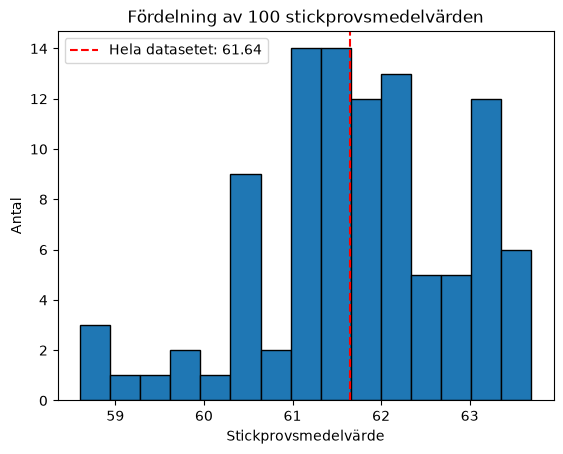

Medelvärde av stickprovsmedelvärden: 61.74
Standardavvikelse: 1.13


In [10]:
import matplotlib.pyplot as plt
population_mean = df['score'].mean()
print(f'Medelvärde i hela datasetet: {population_mean:.2f}')

np.random.seed(123)
sample = np.random.choice(df['score'], size=100, replace=False)
sample_mean = sample.mean()
print(f'Stickprovsmedelvärde: {sample_mean:.2f}')

sample_means = []
for i in range(100):
    sample = np.random.choice(df['score'], size=100, replace=False)
    sample_means.append(sample.mean())

fig, ax = plt.subplots()
ax.hist(sample_means, bins=15, edgecolor='black')
ax.axvline(population_mean, color='red', linestyle='--',
           label=f'Hela datasetet: {population_mean:.2f}')
ax.set_title('Fördelning av 100 stickprovsmedelvärden')
ax.set_xlabel('Stickprovsmedelvärde')
ax.set_ylabel('Antal')
ax.legend()
plt.show()

print(f'Medelvärde av stickprovsmedelvärden: {np.mean(sample_means):.2f}')
print(f'Standardavvikelse: {np.std(sample_means, ddof=1):.2f}')

# Random seed tar inte bort slumpvariationen. 
# Den gör bara att samma slumpmässiga sekvens kan återskapas när du kör programmet igen.

### Uppgift 2 – Bootstrap av medelvärdet

Skapa först en array utan saknade värden:

```python
score = df["score"].dropna().to_numpy()
```
Genomför därefter en bootstrapanalys:
- skapa 1 000 bootstrapstickprov genom att dra observationer från score med återläggning,
- låt varje bootstrapstickprov ha samma storlek som den ursprungliga arrayen,
- beräkna medelvärdet i varje bootstrapstickprov,
- visa bootstrapfördelningen i ett histogram,
- skriv ut det ursprungliga medelvärdet,
- skriv ut bootstrapmedelvärdenas medelvärde och standardavvikelse.

Använd en seed så att resultatet går att reproducera.  

*(Tips: En slumptalsgenerator och indexdragning med rng.integers() kan användas.)*

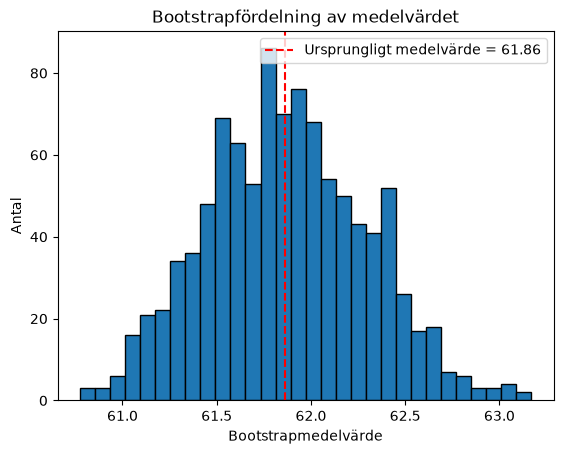

Ursprungligt medelvärde: 61.86152549264858
Bootstrapmedelvärde: 61.87228289688617
Standardavvikelse: 0.4253748114820502


In [11]:
np.random.seed(123)
n_boot = 1_000

obs_mean = score.mean()
boot_means = np.empty(n_boot)

for i in range(n_boot):
    score_star = np.random.choice(score, size=len(score), replace=True)
    boot_means[i] = score_star.mean()


fig, ax = plt.subplots()
ax.hist(boot_means, bins=30, edgecolor='black')

ax.axvline(obs_mean, color='red', linestyle='--',
           label=f'Ursprungligt medelvärde = {obs_mean:.2f}')

ax.set_title('Bootstrapfördelning av medelvärdet')
ax.set_xlabel('Bootstrapmedelvärde')
ax.set_ylabel('Antal')
ax.legend()
plt.show()


print('Ursprungligt medelvärde:', obs_mean)
print('Bootstrapmedelvärde:', boot_means.mean())
print('Standardavvikelse:', boot_means.std(ddof=1))


### Uppgift 3 – Förstå reproducerbar slump

Studera följande kod:

```python
import numpy as np

rng = np.random.default_rng(42)

a = rng.random(3)
b = rng.random(3)

print(a)
print(b)
```
Trots att en seed har angetts innehåller `a` och `b` olika tal.
- Förklara varför resultaten är olika.
- Skapa en ny generator med samma seed.
- Generera sex tal med den nya generatorn.
- Kontrollera att de första tre talen motsvarar `a` och att de sista tre motsvarar `b`.
- Förklara kort vad reproducerbarhet innebär i detta sammanhang.

**Viktigt**: En seed gör inte varje uttag identiskt. Den gör att samma serie av uttag kan återskapas.

In [12]:
rng = np.random.default_rng(42)
a = rng.random(3)
b = rng.random(3)
print(a)
print(b)
rng2 = np.random.default_rng(42)
six_numbers = rng2.random(6)
print(six_numbers)
# Generatorn fortsätter alltså från där den slutade vid föregående anrop. Den börjar inte om från seed-värdet.
# Seed-värdet bestämmer alltså utgångspunkten för slumptalsgeneratorns sekvens, inte att varje enskilt anrop ska ge identiska tal.

[0.77395605 0.43887844 0.85859792]
[0.69736803 0.09417735 0.97562235]
[0.77395605 0.43887844 0.85859792 0.69736803 0.09417735 0.97562235]


## Block B – Konfidensintervall

### Uppgift 4 – Konfidensintervall för ett medelvärde

Skatta ett 95-procentigt konfidensintervall för medelvärdet av `score` i grupp A.

- filtrera fram grupp A,
- ta bort saknade värden i `score`,
- beräkna stickprovsstorlek, medelvärde och stickprovsstandardavvikelse,
- beräkna standardfelet,
- använd normalapproximationen med det kritiska värdet 1,96,
- beräkna intervallets undre och övre gräns.

Redovisa:

- punktestimatet,
- stickprovsstandardavvikelsen,
- standardfelet,
- konfidensintervallet.

Skriv även en kort tolkning av vad intervallet betyder.

Använd stickprovsstandardavvikelsen med `ddof=1`.

In [13]:
group_A = df.loc[df['group'] == 'A', 'score']
n = len(group_A)
mean_A = group_A.mean()
std_A = group_A.std(ddof=1)
se = std_A / np.sqrt(n)

z = 1.96
ci_low = mean_A - z * se
ci_high = mean_A + z * se

print('Stickprovsstorlek:', n)
print('Stickprovsmedelvärde:', mean_A)
print('Stickprovsstandardavvikelse:', std_A)
print('Standardfel:', se)
print(f'95 % konfidensintervall: [{ci_low:.2f}, {ci_high:.2f}]')

# Det beräknade 95-procentiga konfidensintervallet anger ett intervall av rimliga värden för det sanna populationsmedelvärdet i grupp A.
# Om vi upprepade stickprovsdragningen och beräknade ett intervall på samma sätt många gånger,
# skulle ungefär 95 % av dessa intervall innehålla det sanna populationsmedelvärdet.

Stickprovsstorlek: 372
Stickprovsmedelvärde: 61.19193548387097
Stickprovsstandardavvikelse: 12.114191162048385
Standardfel: 0.6280915527887206
95 % konfidensintervall: [59.96, 62.42]


### Uppgift 5 – Konfidensintervall för en andel

Skatta ett 95-procentigt konfidensintervall för andelen kunder som genomfört ett köp i grupp B.

- filtrera fram grupp B,
- ta bort rader där `purchase` saknas,
- beräkna antalet observationer `n`,
- beräkna den observerade andelen köp,
- beräkna standardfelet för en andel,
- använd det kritiska värdet 1,96,
- beräkna intervallets undre och övre gräns.

Redovisa punktestimat, standardfel och konfidensintervall.

Kontrollera även om det förväntade antalet köp och icke-köp är tillräckligt stort för att normalapproximationen ska vara rimlig.

In [14]:
group_B_purchase = df.loc[df['group'] == 'B', 'purchase']
n2 = len(group_B_purchase)
purchase_proportion = group_B_purchase.mean() # eftersom purchase är 0 eller 1 så ger medelvärdet köpandel
se = np.sqrt((purchase_proportion * (1 - purchase_proportion)) / n)

z = 1.96
ci_low = purchase_proportion - z * se
ci_high = purchase_proportion + z * se

expected_purchases = n * purchase_proportion
expected_non_purchases = n * (1 - purchase_proportion)

print('Förväntat antal köp:', expected_purchases)
print('Förväntat antal icke-köp:', expected_non_purchases)

print('Stickprovsstorlek:', n)
print(f'Observerad andel köp: {purchase_proportion:.3f}')
print(f'Standardfel: {se:.4f}')
print(f'95 % konfidensintervall: [{ci_low:.3f}, {ci_high:.3f}]')

# Konfidensintervallet visar ett uppskattat intervall för den sanna andelen kunder i grupp B som genomför ett köp. 
# Med 95 % konfidens täcker intervallet den sanna populationsandelen, enligt den använda metoden.
# Förväntat antal köp och antal ick-köp är båda över 10 vilket är den vanligaste tumregeln.

Förväntat antal köp: 240.29189189189188
Förväntat antal icke-köp: 131.70810810810812
Stickprovsstorlek: 372
Observerad andel köp: 0.646
Standardfel: 0.0248
95 % konfidensintervall: [0.597, 0.695]


### Uppgift 6 – Felsökning: standardavvikelse och standardfel

Koden ska beräkna ett 95-procentigt konfidensintervall för medelvärdet av `score` i grupp A, men standardavvikelsen används på fel sätt.

Kör koden och rätta beräkningen:

```python
import numpy as np
import pandas as pd

df = pd.read_csv("customer_activity.csv")

x = df.loc[df["group"] == "A", "score"].dropna()

mean = x.mean()
sd = x.std()
n = x.shape[0]
z = 1.96

lo = mean - z * sd
hi = mean + z * sd

print(lo, hi)
```

Den rättade lösningen ska:

- beräkna standardfelet,
- använda standardfelet i konfidensintervallet,
- skriva ut medelvärde, standardavvikelse, standardfel och intervall,
- kort förklara skillnaden mellan standardavvikelse och standardfel.

In [15]:
import numpy as np
import pandas as pd

df = pd.read_csv("customer_activity.csv")

x = df.loc[df["group"] == "A", "score"].dropna()

mean = x.mean()
sd = x.std()
se = sd / np.sqrt(n)
n = x.shape[0]
z = 1.96

lo = mean - z * se
hi = mean + z * se

print(lo, hi)

print(f"Medelvärde: {mean:.2f}")
print(f"Standardavvikelse: {sd:.2f}")
print(f"Standardfel: {se:.2f}")
print(f"95 % konfidensintervall: [{lo:.2f}, {hi:.2f}]")

# Standardavvikelse (SD): Visar hur mycket de enskilda observationerna varierar kring medelvärdet.

#Standardfel (SE): Visar hur mycket stickprovsmedelvärdet förväntas variera mellan olika stickprov. 
# Det beskriver alltså osäkerheten i skattningen av populationsmedelvärdet.

60.05248398006591 62.506803551740695
Medelvärde: 61.28
Standardavvikelse: 12.08
Standardfel: 0.63
95 % konfidensintervall: [60.05, 62.51]


## Block C – Grundläggande hypotesprövning

### Uppgift 7 – A/B-test av medelvärden

Undersök om det genomsnittliga värdet på `score` skiljer sig mellan grupp A och grupp B.

- formulera nollhypotes och mothypotes,
- välj en signifikansnivå,
- ta bort saknade värden,
- beräkna antal observationer och medelvärde för respektive grupp,
- genomför ett tvåsidigt Welch t-test för oberoende grupper,
- rapportera teststatistika och p-värde,
- fatta ett beslut utifrån den valda signifikansnivån.

Redovisa även den observerade skillnaden mellan gruppernas medelvärden.

Avsluta med att skilja mellan:

- statistisk signifikans,
- skillnadens praktiska betydelse.

**Tips:** Funktionen `scipy.stats.ttest_ind()` kan användas med `equal_var=False`.

In [19]:
from scipy import stats
# Nollhypotes: Det finns ingen skillnad mellan gruppernas populationsmedelvärden.
# Mothypotes: Det finns en skillnad mellan gruppernas populationsmedelvärden.
alpha = 0.05 # signifikansnivå
df = df.dropna()
group_B = df.loc[df['group'] == 'B', 'score']

n_A = len(group_A)
n_B = len(group_B)
mean_A = group_A.mean()
mean_B = group_B.mean()
mean_diff = mean_B - mean_A

# Welch t-test
t_stat, p_value = stats.ttest_ind(group_A, group_B, equal_var=False, alternative="two-sided")

print(f"Antal observationer i grupp A: {n_A}")
print(f"Antal observationer i grupp B: {n_B}")
print(f"Medelvärde grupp A: {mean_A:.2f}")
print(f"Medelvärde grupp B: {mean_B:.2f}")
print(f"Observerad skillnad (B - A): {mean_diff:.2f}")
print(f"Teststatistika (t): {t_stat:.4f}")
print(f"P-värde: {p_value:.4f}")

if p_value < alpha:
    print("Resultatet är statistiskt signifikant. Nollhypotesen förkastas.")
else:
    print("Resultatet är inte statistiskt signifikant. Nollhypotesen kan inte förkastas.")



Antal observationer i grupp A: 372
Antal observationer i grupp B: 370
Medelvärde grupp A: 61.19
Medelvärde grupp B: 62.10
Observerad skillnad (B - A): 0.91
Teststatistika (t): -1.0448
P-värde: 0.2965
Resultatet är inte statistiskt signifikant. Nollhypotesen kan inte förkastas.


Welch t-testet gav ett p-värde på 0,2965, vilket överstiger den valda signifikansnivån på 0,05. Nollhypotesen kan därför inte förkastas. Det finns inte tillräckligt statistiskt stöd för att gruppernas populationsmedelvärden skiljer sig åt.

Den observerade skillnaden mellan gruppernas medelvärden var 0,91 poäng, där grupp B hade det högre medelvärdet. Skillnaden är liten och resultatet visar inte någon statistiskt signifikant effekt av gruppindelningen. Att resultatet inte är statistiskt signifikant innebär dock inte att grupperna bevisligen är identiska.

### Uppgift 8 – Felsökning: tolkning av p-värde

Följande kod drar en felaktig slutsats:

```python
p_value = 0.07

if p_value < 0.1:
    print("Signifikant på 5%-nivån!")
```

Rätta koden och resonemanget.

- Använd signifikansnivån 5 procent.
- Låt programmet skriva ut en korrekt slutsats.
- Förklara kort varför ett p-värde på `0.07` inte är statistiskt signifikant på 5-procentsnivån.
- Förklara varför detta inte innebär att nollhypotesen har bevisats vara sann.

In [ ]:
p_value = 0.07
if p_value < 0.05:
    print("Resultatet är statistiskt signifikant på 5%-nivån.")
else:
    print("Resultatet är inte statistiskt signifikant på 5%-nivån.")

# Vi har bara otillräckligt statistiskt stöd för att förkasta nollhypotesen vid den valda signifikansnivån.